In [1]:
import pandas as pd
df=pd.read_csv("loan_approval_dataset.csv")
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [2]:
df.columns = df.columns.str.strip()

# Remove unnecessary identifier
df.drop('loan_id', axis=1, inplace=True)

# Inspect original categorical values
for col in ['education', 'self_employed', 'loan_status']:
    print(f"\n{col}:")
    print([repr(value) for value in df[col].unique()])



education:
["' Graduate'", "' Not Graduate'"]

self_employed:
["' No'", "' Yes'"]

loan_status:
["' Approved'", "' Rejected'"]


In [3]:
# Dataset information
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Target distribution
print("\nLoan status distribution:")
print(df['loan_status'].value_counts())

Dataset shape: (4269, 13)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB

Missing valu

In [3]:
cat_col = ['education', 'self_employed', 'loan_status']

for col in cat_col:
    df[col] = df[col].str.strip()

# Verify
for col in cat_col:
    print(col, df[col].unique())

education <StringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str
self_employed <StringArray>
['No', 'Yes']
Length: 2, dtype: str
loan_status <StringArray>
['Approved', 'Rejected']
Length: 2, dtype: str


In [5]:
df['education'] = df['education'].map({
    'Not Graduate': 0,
    'Graduate': 1
})

df['self_employed'] = df['self_employed'].map({
    'No': 0,
    'Yes': 1
})

df['loan_status'] = df['loan_status'].map({
    'Rejected': 0,
    'Approved': 1
})

In [6]:
cat_col = ['education', 'self_employed', 'loan_status']

for col in cat_col:
    print(f"\n{col}:")
    print(df[col].value_counts())


education:
education
Graduate        2144
Not Graduate    2125
Name: count, dtype: int64

self_employed:
self_employed
Yes    2150
No     2119
Name: count, dtype: int64

loan_status:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [6]:
df.isnull().sum()

no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [7]:
print(df[cat_col].head())

   education  self_employed  loan_status
0          1              0            1
1          0              1            0
2          1              0            0
3          1              0            0
4          0              1            0


In [8]:
# Independent variables
X = df.drop('loan_status', axis=1)

# Dependent variable
y = df['loan_status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (4269, 11)
Target shape: (4269,)


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000


0    1
1    0
2    0
3    0
4    0
Name: loan_status, dtype: int64

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (3415, 11)
Testing features: (854, 11)

Training target distribution:
loan_status
1    2125
0    1290
Name: count, dtype: int64

Testing target distribution:
loan_status
1    531
0    323
Name: count, dtype: int64


In [10]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [11]:
y_pred_dt = dt_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).tolist())

print("\nPredicted values:")
print(y_pred_dt[:10])

Actual values:
[0, 0, 0, 1, 1, 1, 1, 0, 1, 0]

Predicted values:
[1 0 0 1 1 1 1 0 1 0]


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Decision Tree Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['Rejected', 'Approved']
))

Decision Tree Performance
Accuracy: 0.9812646370023419
Precision: 0.9849340866290018
Recall: 0.9849340866290018
F1 Score: 0.9849340866290018

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.98      0.98      0.98       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



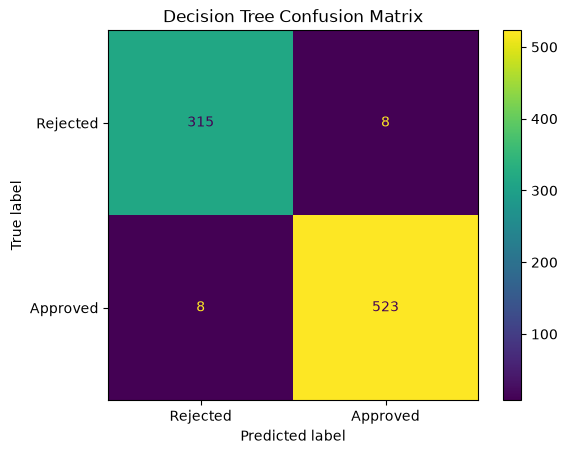

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=['Rejected', 'Approved']
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [14]:
from sklearn.naive_bayes import GaussianNB

# Create Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [15]:
y_pred_nb = nb_model.predict(X_test)

print("Actual values:")
print(y_test.head(10).tolist())

print("\nPredicted values:")
print(y_pred_nb[:10])

Actual values:
[0, 0, 0, 1, 1, 1, 1, 0, 1, 0]

Predicted values:
[1 0 1 1 1 1 1 1 1 0]


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Naive Bayes Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 Score:", f1_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Rejected', 'Approved']
))

Naive Bayes Performance
Accuracy: 0.752927400468384
Precision: 0.721606648199446
Recall: 0.9811676082862524
F1 Score: 0.8316041500399042

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.92      0.38      0.54       323
    Approved       0.72      0.98      0.83       531

    accuracy                           0.75       854
   macro avg       0.82      0.68      0.68       854
weighted avg       0.80      0.75      0.72       854



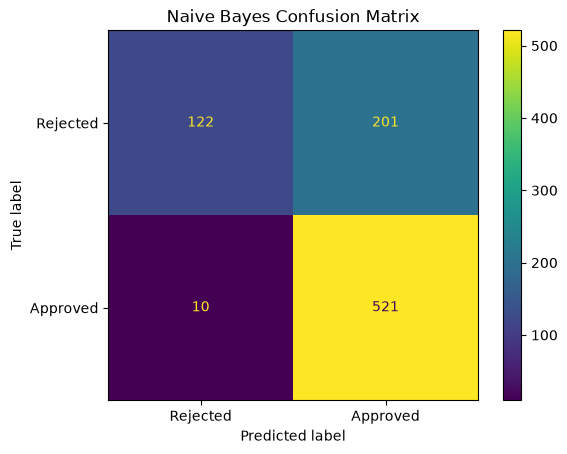

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['Rejected', 'Approved']
)

disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [18]:
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_nb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_nb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_nb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_nb)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.9813,0.9849,0.9849,0.9849
1,Naive Bayes,0.7529,0.7216,0.9812,0.8316
